<a href="https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/numerik/01_numerische_integration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Numerische Integration: Trapez- und Simpson-Regel

Viele Integrale lassen sich nicht geschlossen (analytisch) berechnen. Numerische
Quadraturverfahren approximieren $\int_a^b f(x)\,dx$ stattdessen durch eine gewichtete
Summe von Funktionswerten an diskreten Stuetzstellen.

Wir vergleichen zwei klassische Verfahren an einem Integral mit bekanntem exakten Wert,
$\int_0^\pi \sin(x)\,dx = 2$, um die Konvergenzordnung sichtbar zu machen:

- **Trapezregel**: approximiert $f$ stueckweise linear. Fehlerordnung $O(h^2)$.
- **Simpson-Regel**: approximiert $f$ stueckweise quadratisch (Parabeln). Fehlerordnung $O(h^4)$.

Je groesser der Exponent in der Fehlerordnung, desto schneller sinkt der Fehler bei
feinerer Unterteilung -- das macht Simpson bei glatten Funktionen deutlich effizienter.

Numerische Integration von sin(x) auf [0, pi], exakter Wert = 2
   n |       Trapez |  Fehler Trapez |      Simpson |  Fehler Simpson
   2 |   1.57079633 |       4.29e-01 |   2.09439510 |        9.44e-02
   4 |   1.89611890 |       1.04e-01 |   2.00455975 |        4.56e-03
   8 |   1.97423160 |       2.58e-02 |   2.00026917 |        2.69e-04
  16 |   1.99357034 |       6.43e-03 |   2.00001659 |        1.66e-05
  32 |   1.99839336 |       1.61e-03 |   2.00000103 |        1.03e-06
  64 |   1.99959839 |       4.02e-04 |   2.00000006 |        6.45e-08


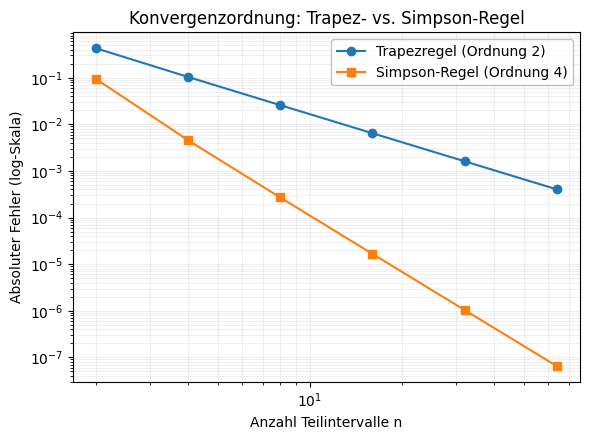

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})


def f(x):
    return np.sin(x)


A, B = 0.0, np.pi
EXAKT = 2.0  # Integral von sin(x) auf [0, pi]


def trapezregel(f, a, b, n):
    x = np.linspace(a, b, n + 1)
    h = (b - a) / n
    y = f(x)
    return h * (0.5 * y[0] + 0.5 * y[-1] + np.sum(y[1:-1]))


def simpsonregel(f, a, b, n):
    if n % 2 != 0:
        raise ValueError("Simpson-Regel benoetigt eine gerade Anzahl Teilintervalle n")
    x = np.linspace(a, b, n + 1)
    h = (b - a) / n
    y = f(x)
    s = y[0] + y[-1] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-1:2])
    return h / 3 * s


def main():
    print("Numerische Integration von sin(x) auf [0, pi], exakter Wert = 2")
    print(f"{'n':>4} | {'Trapez':>12} | {'Fehler Trapez':>14} | {'Simpson':>12} | {'Fehler Simpson':>15}")

    ns = [2, 4, 8, 16, 32, 64]
    trapez_err = []
    simpson_err = []
    for n in ns:
        t = trapezregel(f, A, B, n)
        s = simpsonregel(f, A, B, n)
        et = abs(t - EXAKT)
        es = abs(s - EXAKT)
        trapez_err.append(et)
        simpson_err.append(es)
        print(f"{n:>4} | {t:>12.8f} | {et:>14.2e} | {s:>12.8f} | {es:>15.2e}")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.loglog(ns, trapez_err, "o-", label="Trapezregel (Ordnung 2)")
    ax.loglog(ns, simpson_err, "s-", label="Simpson-Regel (Ordnung 4)")
    ax.set_xlabel("Anzahl Teilintervalle n")
    ax.set_ylabel("Absoluter Fehler (log-Skala)")
    ax.set_title("Konvergenzordnung: Trapez- vs. Simpson-Regel")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
    fig.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()